In [1]:
import os, sys
import ROOT as rt
import json
## user define
sys.path.append(".")
sys.path.append("./Utils")
from SystHelper import *
from rpy2.robjects.packages import importr
from rpy2.robjects import FloatVector
setting={}
with open('config/Settrain.json') as json_file:
    data = json.load(json_file)
    setting=data
    
INPUTDIR = sys.argv[1]
ERA = sys.argv[2]
REGION = sys.argv[3]
ALL_MASSES = setting["ALL_MASSES"]
# for dev
# INPUTDIR = "/eos/user/h/hkwon/SWAN_projects/Zpeak/Outputs/DNN/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/Preselection/20230727lep/Presel/DNN/"
# ERA = "ee16"
# INPUTDIR += ERA
# REGION = "SR"

Welcome to JupyROOT 6.28/00


In [2]:
def get_str_lumi_channel(era):
    if("mm" in era):
        str_channel="#mu#mu"          
    if("ee" in era):
        str_channel="ee"               
    if("em" in era):
        str_channel="e#mu"
    if "16" in era:
        str_lumi="37.33"
    if "16pre" in era:
        str_lumi="19.52" 
    if "16post" in era:
        str_lumi="16.81"                 
    if "17" in era:
        str_lumi="41.48"
    if "18" in era:
        str_lumi="59.83"
    return str_channel, str_lumi

In [3]:
out_dir = "Outputs/Syst/"+ERA+"/"+REGION

os.system("mkdir -p "+out_dir+"/AN")
os.system("mkdir -p "+out_dir+"/root_files")

def draw_sys_ratio(ERA, f, process, list_sys, mass, updown="Up", smoothed = False):
    str_channel, str_lumi = get_str_lumi_channel(ERA)
    c=rt.TCanvas("", "", 800, 800)
    c.SetGrid()
    c.SetLeftMargin(0.12)
#     c.SetRightMargin(0.3)
    rt.gStyle.SetPalette(rt.kRainBow)
    rt.gStyle.SetOptStat(0)
    l = rt.TLegend(0.6,0.7,0.89,0.89)
    l.SetBorderSize(0)
    h_nom = f.Get("signal_region/"+process)
    n_h_nom = h_nom.Integral()
    list_hist=[] # kind of hack..(?) hist object seems to remain to the end
    list_hist_clone=[]
    for s in list_sys:
        h = f.Get("signal_region/"+process+"_"+s+updown)
        list_hist.append(h)
        h_new = h.Clone("")
        list_hist_clone.append(h_new)
        h_new.SetTitle("")
        h_new.GetYaxis().SetTitle("Sys/Nom")
        h_new.GetXaxis().SetTitle("DNN score")
        h_new.SetLineWidth(3)
        h_new.SetFillColor(0)
        n_h_new = h_new.Integral()
        eff = n_h_new/n_h_nom
        h_new.Divide(h_nom)
        if not "met" in s and not "hdamp" in s and not "UE" in s and not "scale" in s or smoothed==False:
            l.AddEntry(h_new, s+" "+updown+" (avg. "+str(round((eff-1),2)*100)+"%)", "l")
            l.SetTextSize(0.02)
            h_new.GetYaxis().SetRangeUser(0.8, 1.2)
            h_new.Draw("plc same hist")
        else:
            h = f.Get("signal_region/"+process+"_"+s+"_smoothed"+updown)
            list_hist.append(h)
            h_new = h.Clone("")
            list_hist_clone.append(h_new)
            h_new.SetTitle("")
            h_new.GetYaxis().SetTitle("Sys/Nom")
            h_new.GetXaxis().SetTitle("DNN score")
            h_new.SetLineWidth(3)
            h_new.SetFillColor(0)
            n_h_new = h_new.Integral()
            eff = n_h_new/n_h_nom
            h_new.Divide(h_nom)
            l.AddEntry(h_new, s+" smoothed "+updown+" (avg. "+str(round((eff-1),2)*100)+"%)", "l")
            l.SetTextSize(0.02)
            h_new.GetYaxis().SetRangeUser(0.8, 1.2)
            h_new.Draw("plc same hist")            
            
    l.Draw()
    latex=rt.TLatex()
    latex.DrawLatexNDC( 0.43,0.85, "#scale[0.8]{#font[42]{"+process+"}}") 
    latex.DrawLatexNDC(0.71, 0.92, "#font[42]{#scale[0.8]{"+str_lumi+" fb^{-1}(13 TeV)}}");
    latex.DrawLatexNDC(0.13, 0.92, "#font[62]{CMS}#font[42]{#it{#scale[0.8]{ Preliminary}}}");
    latex.DrawLatexNDC(0.15,0.85, "#scale[0.8]{#font[42]{"+str_channel+" channel}}") 
    c.Draw()
    if smoothed==True and mass=="Zp-2500_CH-345":
        c.SaveAs(out_dir+"/AN/"+mass+process+updown+"_syst_by_process.pdf")
    else:
        c.SaveAs(out_dir+"/"+mass+process+updown+"_syst_by_process.pdf")
    return c

In [4]:
import math
def draw_sys_ratio_bysource(ERA, f, processes, s, mass, smoothed = False):
#     f.ls()
    str_channel, str_lumi = get_str_lumi_channel(ERA)
    c=rt.TCanvas("", "", 800, 800)
    c.SetGrid()
    c.SetLeftMargin(0.12)
#     c.SetRightMargin(0.3)
    rt.gStyle.SetPalette(rt.kRainBow)
    rt.gStyle.SetOptStat(0)
    l = rt.TLegend(0.7,0.7,0.89,0.89)
    l.SetBorderSize(0)

    list_hist=[] # kind of hack..(?) hist object seems to remain to the end
    list_hist_clone=[]
    dic_smooth={}
    for i, process in enumerate(processes):
        h_nom = f.Get("signal_region/"+process)    
        h_u = f.Get("signal_region/"+process+"_"+s+"Up")
        h_d = f.Get("signal_region/"+process+"_"+s+"Down")
        list_hist.append(h_u)
        list_hist.append(h_d)
        h_u_new = h_u.Clone("")
        h_d_new = h_d.Clone("")
        list_hist_clone.append(h_u_new)
        list_hist_clone.append(h_d_new)              
        h_u_new.SetTitle("")
        h_u_new.GetYaxis().SetTitle("Sys/Nom")
        h_u_new.GetXaxis().SetTitle("DNN score")
        h_u_new.SetLineWidth(2)
        h_d_new.SetLineWidth(2)
        h_u_new.SetLineStyle(1)
        h_d_new.SetLineStyle(2)    
        h_u_new.SetLineColor(i+1)
        h_d_new.SetLineColor(i+1) 
        h_u_new.Divide(h_nom)
        h_d_new.Divide(h_nom)          
        if not "met" in s and not "hdamp" in s and not "UE" in s and not "scale" in s or smoothed==False:
            l.AddEntry(h_u_new, process+" "+s+" Up", "l")
            l.AddEntry(h_d_new, process+" "+s+" Down", "l")
            h_u_new.GetYaxis().SetRangeUser(0.8, 1.3)
            h_u_new.Draw("same hist")
            h_d_new.Draw("same hist")
            if "scale" in s and "e" in ERA:
                h_nom_data = f.Get("signal_region/data_obs")
                h_u_data = f.Get("signal_region/data_"+s+"Up")
                h_d_data = f.Get("signal_region/data_"+s+"Down")
                list_hist.append(h_u_data)
                list_hist.append(h_d_data)
                h_u_data_new = h_u_data.Clone("")
                h_d_data_new = h_d_data.Clone("")
                list_hist_clone.append(h_u_data_new)
                list_hist_clone.append(h_d_data_new)
                h_u_data_new.Divide(h_nom_data)
                h_d_data_new.Divide(h_nom_data)
                h_u_new.Divide(h_u_data_new)
                h_d_new.Divide(h_d_data_new)
            w, w_data, yup, ydown = [[] for _ in range(4)]
            # fill dictionary
            for nb in range(h_d_new.GetNbinsX()):
                w.append(h_nom.GetBinContent(nb+1))  
                if "scale" in s:
                    w_data.append(h_nom_data.GetBinContent(nb+1))  
                yup.append(h_u_new.GetBinContent(nb+1)) 
                ydown.append(h_d_new.GetBinContent(nb+1))  
            
            dic_smooth[process+s+"Nom"] = w
            dic_smooth[process+s+"NomData"] = w_data
            dic_smooth[process+s+"Up"] = yup
            dic_smooth[process+s+"Down"] = ydown 
        
        else:
            h_smoothed_u = f.Get("signal_region/"+process+"_"+s+"_smoothedUp")
            h_smoothed_d = f.Get("signal_region/"+process+"_"+s+"_smoothedDown")
            list_hist.append(h_smoothed_u)
            list_hist.append(h_smoothed_d)
            h_smoothed_u_new = h_smoothed_u.Clone("")
            h_smoothed_d_new = h_smoothed_d.Clone("")
            list_hist_clone.append(h_smoothed_u_new)
            list_hist_clone.append(h_smoothed_d_new)
            h_smoothed_u_new.Divide(h_nom)
            h_smoothed_d_new.Divide(h_nom)
            h_smoothed_u_new.SetTitle("")
            h_smoothed_u_new.GetYaxis().SetTitle("Sys/Nom")
            h_smoothed_u_new.GetXaxis().SetTitle("DNN score")            
            h_smoothed_u_new.SetLineWidth(2)    
            h_smoothed_d_new.SetLineWidth(2)    
            h_smoothed_u_new.SetLineStyle(1)    
            h_smoothed_d_new.SetLineStyle(2)    
            h_smoothed_u_new.SetLineColor(i+1)
            h_smoothed_d_new.SetLineColor(i+1)
            h_smoothed_u_new.GetYaxis().SetRangeUser(0.8, 1.3)
            l.AddEntry(h_smoothed_u_new, process+" "+s+" smoothed Up", "l")
            l.AddEntry(h_smoothed_d_new, process+" "+s+" smoothed Down", "l")
            h_smoothed_u_new.Draw("same hist")
            h_smoothed_d_new.Draw("same hist")
             

                
    l.Draw()
    latex=rt.TLatex()
    latex.DrawLatexNDC(0.71, 0.92, "#font[42]{#scale[0.8]{"+str_lumi+" fb^{-1}(13 TeV)}}");
    latex.DrawLatexNDC(0.13, 0.92, "#font[62]{CMS}#font[42]{#it{#scale[0.8]{ Preliminary}}}");
    latex.DrawLatexNDC(0.15,0.85, "#scale[0.8]{#font[42]{"+str_channel+" channel}}") 
    
#     latex.DrawLatexNDC( 0.13,0.85, "#scale[0.8]{#font[42]{}}")    
    c.Draw()
    if smoothed==True and mass=="Zp-2500_CH-345":
        c.SaveAs(out_dir+"/AN/"+mass+s+"_syst_by_source.pdf")
    else:
        c.SaveAs(out_dir+"/"+mass+s+"_syst_by_source.pdf")
    return c, dic_smooth

In [5]:
masses = ALL_MASSES
masses = ["Zp-2500_CH-345"]

# Draw by source

In [6]:
limma = importr("limma", lib_loc="~/Rpackages")

In [7]:
def write_sys_hist(out_file, h1, h2):
    f = rt.TFile(out_file, "UPDATE") 
    f.cd("signal_region")
#     h1.Write("zp_"+sys+"Up", rt.TObject.kWriteDelete)
#     h2.Write("zp_"+sys+"Down", rt.TObject.kWriteDelete)
    h1.Write()
    h2.Write()  

['l1prefiring', 'pu', 'effrecoSF', 'll_eff', 'met', 'trig_eff', 'scale', 'metue', 'btagSF']
ttbar [699.6155589727717, 318.4428412764972, 161.80291057365042, 94.30914137675308, 62.71216664584115, 40.689428370146935, 26.19686113685004, 20.523442062280655, 17.06500201322672, 16.876445187511948, 13.32905910865869, 12.743364373894153, 11.827017343286952, 12.502214115776686, 11.89495448321536, 13.270720728163356, 15.46583563235181, 16.2482868068738, 14.264114792813201, 6.8478398822141795]  [1] 1.0395472 1.0222402 1.0254322 1.0154935 1.0354888 1.0100972 1.0509256
 [8] 1.0025174 1.0259596 0.9935966 1.0706202 1.0013912 1.0246611 0.9987503
[15] 1.0296040 1.0131197 0.9900317 1.0173033 0.9898386 1.0102306
 [1.03954719 1.02224017 1.02173329 1.02398866 1.02271258 1.02099239
 1.01886055 1.0143037  1.01134043 1.01126249 1.01047603 1.01035369
 1.00937946 1.00854439 1.00782936 1.00718925 1.00652139 1.00576944
 1.00493259 1.00400574] [0.95813658 0.97348086 0.97911271 0.97711551 0.97101813 0.96645626
 0.9

zp [0.11203146242769435, 0.13313749741064385, 0.1604323679348454, 0.18530519830528647, 0.15913365635788068, 0.11477933550486341, 0.11188719724304974, 0.13774690055288374, 0.10259689620579593, 0.08707052859244868, 0.10752524132840335, 0.12903670192463323, 0.12088717316510156, 0.17114913620753214, 0.19208832160802558, 0.2618155447416939, 0.4786423107725568, 0.7901772593613714, 1.9076252449012827, 7.18276119674556]  [1] 0.9989744 0.9827957 1.0000000 0.9938272 1.0102041 0.9705882 1.0540541
 [8] 1.0000000 0.9375000 1.0645161 0.9166667 1.1875000 0.8947368 1.1176471
[15] 0.9333333 0.9259259 1.0294118 1.0000000 0.9705882 0.9794329
 [0.99650726 0.9925066  0.99336228 0.99684747 0.99254906 0.99408326
 0.99715426 1.01030374 1.02652497 1.04576527 1.08782412 1.04249915
 1.0237094  1.02908491 1.02379679 1.01672388 1.00832705 0.99890249
 0.98846415 0.97709974] [1.00004183 1.00153328 1.00088153 0.99674866 0.99834048 1.00408709
 1.0073217  1.00788549 1.0068262  1.00446875 1.00138408 0.99856895
 0.993496

Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345l1prefiring_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345pu_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345effrecoSF_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345ll_eff_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345met_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345trig_eff_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345scale_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345metue_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345btagSF_syst_by_source.pdf

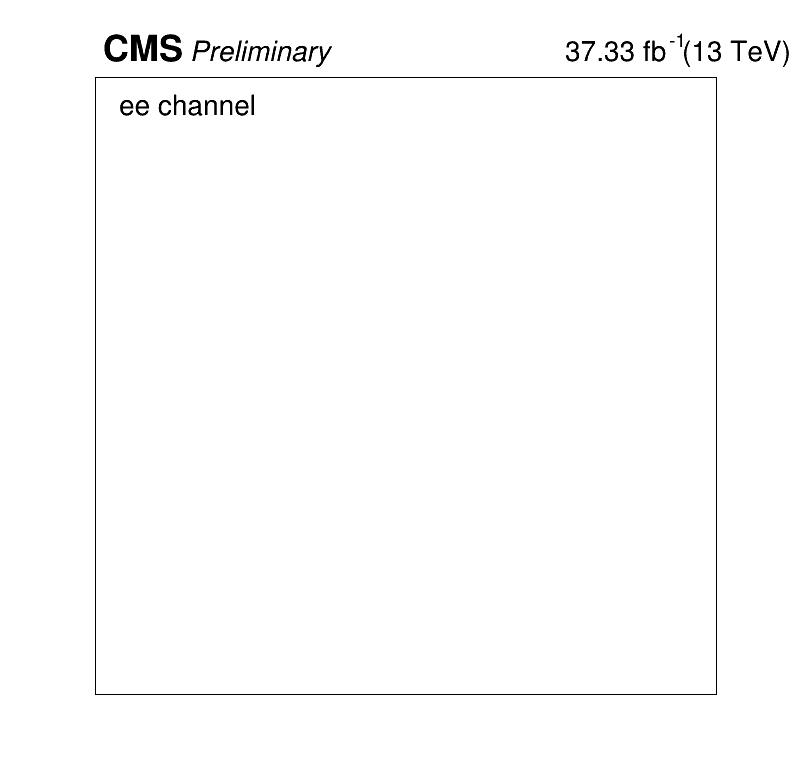

In [8]:
x = FloatVector([0.025, 0.075, 0.125, 0.175, 0.225, 0.275, 0.325, 0.375, 0.425, 0.475, 0.525, 0.575, 0.625, 0.675, 0.725, 0.775, 0.825, 0.875, 0.925, 0.975])
import math
for mass in masses:
    in_file = INPUTDIR+"/"+REGION+"/root_files/shape_v1_20230430wp80_ANv3"+mass+"_v1.root"
    out_file = out_dir+"/root_files/"+"shape_v1_20230430wp80_ANv3"+mass+"_smoothed_v1.root"
    os.system("cp "+in_file+" "+out_file)

    f = rt.TFile(in_file)

    rt.gDirectory.cd("signal_region")

    processes = ["ttbar", "ww", "zp"]
#     list_sys = get_sys_list()
#     list_sys.remove("scale")
#     list_sys = ["l1prefiring", "pu", "ll_eff", "met", "trig_eff", "toppt", "scale", "metue", "btagSF", "hdamp", "UE"]
    list_sys = ["l1prefiring", "pu", "effrecoSF", "ll_eff", "met", "trig_eff", "scale", "metue", "btagSF"]
#     list_sys = ["scale"]
    print(list_sys)
    for sys in list_sys:
        c, dic_smooth = draw_sys_ratio_bysource(ERA, f, processes, sys, mass)
        if "met" in sys or "hdamp" in sys or "UE" in sys or "scale" in sys:
            for process in processes:
                yup = FloatVector(dic_smooth[process+sys+'Up'])
                ydown = FloatVector(dic_smooth[process+sys+'Down'])
                n = dic_smooth[process+sys+'Nom']
                n1 = n
                if "scale" in sys:
                    n_data = dic_smooth[process+sys+'NomData']
                    n1 = n_data
                w = np.sqrt(n1)
                w = FloatVector(w)
                lup = limma.weightedLowess(x, yup, w, span=0.4, output_style="lowess")
                ldown = limma.weightedLowess(x, ydown, w, span=0.4, output_style="lowess")
                smoothed_up = np.array(lup[0])
                smoothed_up[np.isnan(smoothed_up)] = 1
                smoothed_down = np.array(ldown[0])
                print(process, n, yup, smoothed_up, smoothed_down)
                nbin = 20
                h_Up = rt.TH1D(process+"_"+sys+"_smoothedUp", process+"_"+sys+"_smoothedUp", nbin, 0, 1)           
                h_Down = rt.TH1D(process+"_"+sys+"_smoothedDown", process+"_"+sys+"_smoothedDown", nbin, 0, 1)           
                for nb in range(nbin):
                    # average
                    avg = (math.fabs(1-smoothed_up[nb])+math.fabs(1-smoothed_down[nb]))/2
                    h_Up.SetBinContent(nb+1, n[nb]*(1+avg))
                    h_Down.SetBinContent(nb+1, n[nb]*(1-avg))
                    print((1+avg))
                    print((1-avg))
                write_sys_hist(out_file, h_Up, h_Down)

Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-345l1prefiring_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-345pu_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-345effrecoSF_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-345ll_eff_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-345met_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-345trig_eff_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-345scale_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-345metue_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-3

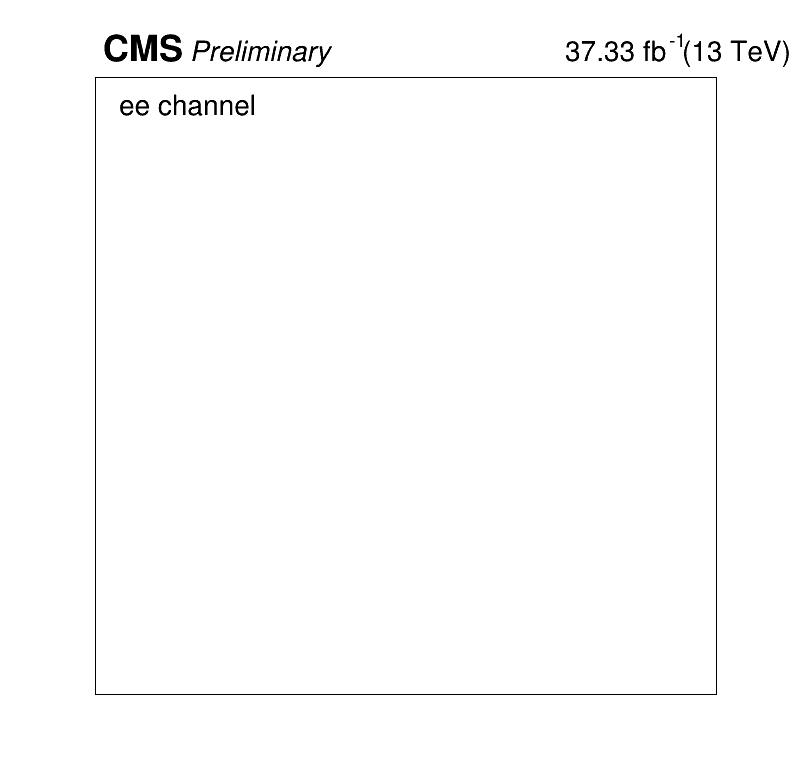

In [9]:
for mass in masses:
    out_file = out_dir+"/root_files/"+"shape_v1_20230430wp80_ANv3"+mass+"_smoothed_v1.root"

    f = rt.TFile(out_file)

    rt.gDirectory.cd("signal_region")

    processes = ["ttbar", "ww", "zp"]
#     processes = ["ttbar"]
#     list_sys = ["l1prefiring", "pu", "ll_eff", "met", "trig_eff", "toppt", "scale", "metue", "btagSF", "hdamp", "UE"]
    list_sys = ["l1prefiring", "pu", "effrecoSF", "ll_eff", "met", "trig_eff", "scale", "metue", "btagSF"]
#     list_sys = ["scale"]
    for sys in list_sys:
        c, dic_smooth = draw_sys_ratio_bysource(ERA, f, processes, sys, mass, True)


 # Draw by process

Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345ttbarUp_syst_by_process.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345ttbarDown_syst_by_process.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-345ttbarUp_syst_by_process.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-345ttbarDown_syst_by_process.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345wwUp_syst_by_process.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345wwDown_syst_by_process.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-345wwUp_syst_by_process.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/AN/Zp-2500_CH-345wwDown_syst_by_process.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee16/SR/Zp-2500_CH-345zp

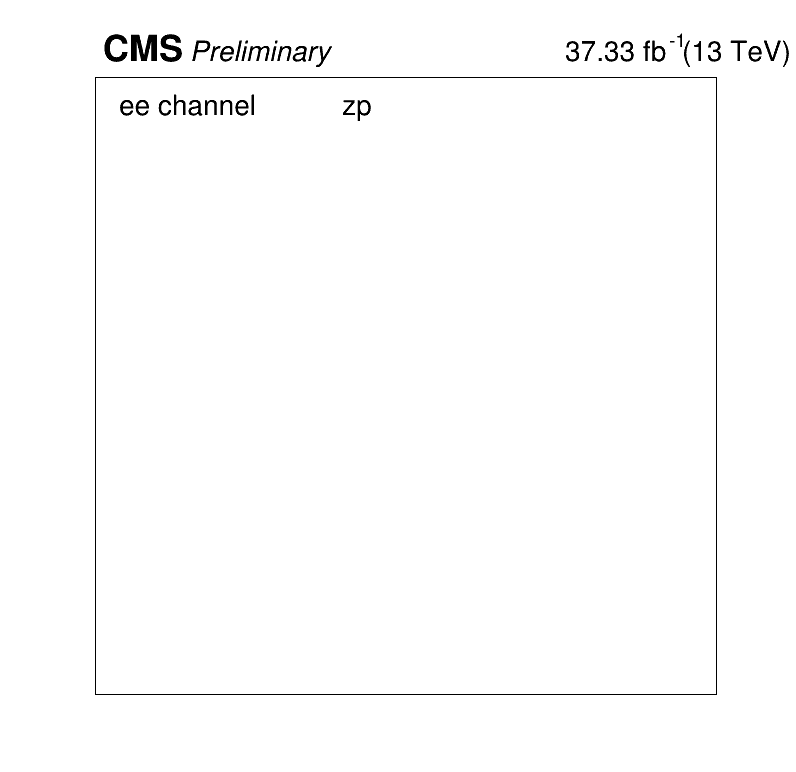

In [10]:
for mass in masses:
    out_file = out_dir+"/root_files/"+"shape_v1_20230430wp80_ANv3"+mass+"_smoothed_v1.root"

    f = rt.TFile(out_file)

    rt.gDirectory.cd("signal_region")

    processes = ["ttbar", "ww", "zp"]
#     processes = ["ttbar"]
#     list_sys = ["l1prefiring", "pu", "ll_eff", "met", "trig_eff", "toppt", "scale", "metue", "btagSF", "hdamp", "UE"]
    list_sys = ["l1prefiring", "pu", "effrecoSF", "ll_eff", "met", "trig_eff", "scale", "metue", "btagSF"]
    for process in processes:
        c = draw_sys_ratio(ERA, f, process, list_sys, mass, updown="Up", smoothed = False)        
        c = draw_sys_ratio(ERA, f, process, list_sys, mass, updown="Down", smoothed = False)        
        c = draw_sys_ratio(ERA, f, process, list_sys, mass, updown="Up", smoothed = True)        
        c = draw_sys_ratio(ERA, f, process, list_sys, mass, updown="Down", smoothed = True)